In [2]:
!pip install geopandas
!pip install geodatasets
!pip install contextily
!pip install geoplot
!pip install geopy
!pip install folium

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.0/24.0 MB 2.3 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 6.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 6.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 23.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 14.0 MB/s eta 0:00:00a 0:00:01


In [3]:
!pip install -q geopandas
!pip install -q geodatasets
!pip install -q contextily
!pip install -q geoplot
!pip install -q geopy
!pip install -q folium

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import geopandas as gpd
import contextily as ctx
import geoplot.crs as gcrs
import geoplot as gplt
import pyproj

# NEW YORK

#### Inlezen van bestanden via geodatasets - NEW YORK

In [5]:
from geodatasets import get_path
path_to_file = get_path("nybb")

Extracting 'nybb_16a/nybb.shp' from '/home/jovyan/.cache/geodatasets/nybb_16a.zip' to '/home/jovyan/.cache/geodatasets/nybb_16a.zip.unzip'
Extracting 'nybb_16a/nybb.shx' from '/home/jovyan/.cache/geodatasets/nybb_16a.zip' to '/home/jovyan/.cache/geodatasets/nybb_16a.zip.unzip'
Extracting 'nybb_16a/nybb.dbf' from '/home/jovyan/.cache/geodatasets/nybb_16a.zip' to '/home/jovyan/.cache/geodatasets/nybb_16a.zip.unzip'
Extracting 'nybb_16a/nybb.prj' from '/home/jovyan/.cache/geodatasets/nybb_16a.zip' to '/home/jovyan/.cache/geodatasets/nybb_16a.zip.unzip'


#### Afstanden berekenen - oefening

Schrijf een functie die voor een gegeven GeoDataFrame de afstandsmatrix (distance matrix) berekent voor de centroids van alle locaties.  Gebruik de .distance() functie.  Het resultaat is ongeveer als volgt:

![alt text](../IMAGES/distancematrix.png "Optionele titel")

In [6]:
# Oplossing
gdf = gpd.read_file(path_to_file)
gdf.head()

,BoroCode,BoroName,Shape_Leng,Shape_Area,geometry
0,5,Staten Island,330470.010332,1.623820e+09,"MULTIPOLYGON (((970217.022 145643.332, 970227...."
1,4,Queens,896344.047763,3.045213e+09,"MULTIPOLYGON (((1029606.077 156073.814, 102957..."
2,3,Brooklyn,741080.523166,1.937479e+09,"MULTIPOLYGON (((1021176.479 151374.797, 102100..."
3,1,Manhattan,359299.096471,6.364715e+08,"MULTIPOLYGON (((981219.056 188655.316, 980940...."
4,2,Bronx,464392.991824,1.186925e+09,"MULTIPOLYGON (((1012821.806 229228.265, 101278..."


Om afstanden te berekenen moeten we een projected coördinatensysteem zoals EPSG:32618 voor New York gebruiken.

In [7]:
# Check het CRS
gdf.crs

<Projected CRS: EPSG:2263>
Name: NAD83 / New York Long Island (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - New York - counties of Bronx; Kings; Nassau; New York; Queens; Richmond; Suffolk.
- bounds: (-74.26, 40.47, -71.8, 41.3)
Coordinate Operation:
- name: SPCS83 New York Long Island zone (US survey foot)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

Het CRS EPSG:2263 is specifiek ontworpen voor New York dus dat is goed!

In [8]:
# Een kolom met de centroids toevoegen
gdf['centroid'] = gdf.centroid

In [9]:
gdf.head()

,BoroCode,BoroName,Shape_Leng,Shape_Area,geometry,centroid
0,5,Staten Island,330470.010332,1.623820e+09,"MULTIPOLYGON (((970217.022 145643.332, 970227....",POINT (941639.45 150931.991)
1,4,Queens,896344.047763,3.045213e+09,"MULTIPOLYGON (((1029606.077 156073.814, 102957...",POINT (1034578.078 197116.604)
2,3,Brooklyn,741080.523166,1.937479e+09,"MULTIPOLYGON (((1021176.479 151374.797, 102100...",POINT (998769.115 174169.761)
3,1,Manhattan,359299.096471,6.364715e+08,"MULTIPOLYGON (((981219.056 188655.316, 980940....",POINT (993336.965 222451.437)
4,2,Bronx,464392.991824,1.186925e+09,"MULTIPOLYGON (((1012821.806 229228.265, 101278...",POINT (1021174.79 249937.98)


In [10]:
# Afstand tussen bijvoorbeeld Staten Island en Queens:
straight_distance = gdf.iloc[0]['centroid'].distance(gdf.iloc[1]['centroid'])
print(f"De afstand tussen Staten Island en Queens is {straight_distance} voet.")
print(f"Dit komt overeen met {straight_distance*.3048} meter.")

De afstand tussen Staten Island en Queens is 103781.53527578666 voet.
Dit komt overeen met 31632.61195205978 meter.


In [11]:
# Stramien: we berekenen voor elke rij centroid de afstand tot de andere rij centroids en slaan dit op in de juiste kolom
for i in range(len(gdf)):
    citypart_one = gdf.iloc[i]['BoroName']
    for j in range(len(gdf)):
        citypart_two = gdf.iloc[j]['BoroName']
        distance_between_cityparts = gdf.iloc[i]['centroid'].distance(gdf.iloc[j]['centroid'])*.3048
        gdf.at[i,citypart_two] = distance_between_cityparts

In [12]:
gdf[['BoroName','Staten Island','Queens','Brooklyn','Manhattan','Bronx']].head(10)

,BoroName,Staten Island,Queens,Brooklyn,Manhattan,Bronx
0,Staten Island,0.000000,31632.611952,18798.507515,26897.912002,38708.467248
1,Queens,31632.611952,0.000000,12963.282350,14752.707852,16610.190288
2,Brooklyn,18798.507515,12963.282350,0.000000,14809.104053,24082.744174
3,Manhattan,26897.912002,14752.707852,14809.104053,0.000000,11924.088261
4,Bronx,38708.467248,16610.190288,24082.744174,11924.088261,0.000000


# VISUALISEREN VAN HET INKOMEN IN DE WERELD

In [13]:
## De wereld inladen
world = gpd.read_file('GEODATA/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp')

Zoek in de dataset naar een property die te maken heeft met de inkomensgroep waartoe het land behoort.  Plot de wereldkaar en geef elk land een kleurtje in functie van deze parameter.

AttributeError: 'GeoDataFrame' object has no attribute 'legend'

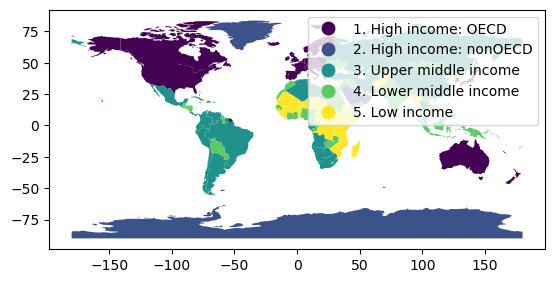

In [17]:
# Oplossing

# De feature INCOME_GRP in geospatiale datasets verwijst meestal naar de 
# inkomensgroep van een land, wat een classificatie is van landen op basis 
# van hun bruto nationaal inkomen (BNI) per hoofd van de bevolking. 

world.plot(column='INCOME_GRP', legend=True, cmap='viridis')

# Legende buiten de grafiek plaatsen
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1))

# Layout aanpassen zodat er ruimte is voor de legende
plt.tight_layout()

# Grafiek weergeven
plt.show()

# VISUALISATIE VAN DE BEVOLKINGSDICHTHEID IN DE WERELD

Gebruik de GeoDataset die je hierbocen hebt gebruikt om het inkomen in de wereld te visualiseren nu om de bevolkingsdichtheid in de wereld te visualiseren.  Zorg voor een passend kleurschema, en pas eventueel de schaal aan.  Ga ook na of het CRS geschikt is voor de opdracht.  Als opwarmer kan je even de populatiedichtheid in België berekenen:

De geometrieën van de shapefile zijn momenteel in een geografische CRS (zoals EPSG:4326). Wanneer je operaties uitvoert zoals het berekenen van oppervlakte, afstand of andere ruimtelijke bewerkingen, zijn resultaten gebaseerd op graden onnauwkeurig, omdat een graden-coördinaat geen afstand in meters of kilometers aangeeft.

Om dit probleem op te lossen, moet je de geometrieën transformeren naar een projected CRS dat in meters of kilometers werkt. Een veelgebruikt CRS voor dit soort operaties is EPSG:3857 (Web Mercator), maar er zijn ook andere projecties beschikbaar, afhankelijk van de regio of het type analyse.  We kiezen EPSG 3035 (https://epsg.io/3035) omdat dit geschikt is voor België en een accuraatheid van 1 meter heeft.

In [40]:
# Transformeer de geometrieën naar een Equal Area Projectie (ETRS89 / LAEA Europe)
world_equal_area = world.to_crs(epsg=3035)

# Selecteer België in de getransformeerde dataset
belgium = world_equal_area[world_equal_area['SOVEREIGNT'] == 'Belgium']

# Bereken de oppervlakte in vierkante meters
belgium_area_m2 = belgium.geometry.area.iloc[0]

# Zet de oppervlakte om naar vierkante kilometers
belgium_area_km2 = belgium_area_m2 / 1e6

print(f"Oppervlakte van België: {belgium_area_km2} km²")

# Population in Belgium
population_belgium = belgium['POP_EST'].iloc[0]
print(f"Population in Belgium: {population_belgium}")
print(f"Population density in Belgium: {population_belgium / belgium_area_km2} hab/km² ")

Oppervlakte van België: 30125.663016421462 km²
Population in Belgium: 11484055.0
Population density in Belgium: 381.2050541008859 hab/km² 


In [41]:
# Nu voor alle landen...
# Bereken de oppervlakte in vierkante kilometers voor alle landen
world_equal_area['area_km2'] = world_equal_area.geometry.area / 1e6  # oppervlakte in km²

# Bereken de bevolkingsdichtheid (populatie per km²) voor alle landen
world_equal_area['population_density'] = world_equal_area['POP_EST'] / world_equal_area['area_km2']

# Toon de eerste paar rijen om de resultaten te bekijken
print(world_equal_area[['SOVEREIGNT', 'area_km2', 'POP_EST', 'population_density']].head())

# Check resultaat België
belgium = world_equal_area[world_equal_area['SOVEREIGNT']=="Belgium"]
print('\n\n',belgium[['SOVEREIGNT', 'area_km2', 'POP_EST', 'population_density']])

                    SOVEREIGNT      area_km2      POP_EST  population_density
0                         Fiji  1.916776e+04     889953.0           46.429687
1  United Republic of Tanzania  9.335536e+05   58005463.0           62.134047
2               Western Sahara  9.586239e+04     603253.0            6.292906
3                       Canada  1.003334e+07   37589262.0            3.746435
4     United States of America  9.512162e+06  328239523.0           34.507353


     SOVEREIGNT      area_km2     POP_EST  population_density
129    Belgium  30125.663016  11484055.0          381.205054


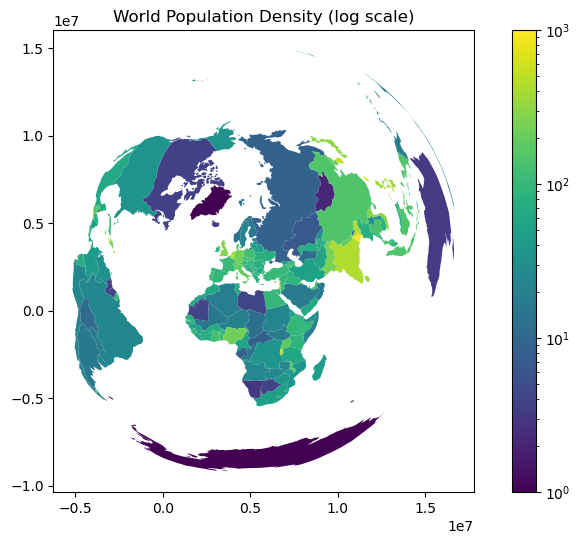

In [43]:
# Plot
from matplotlib.colors import LogNorm

# Stel een logaritmische schaal in en beperk extreme waarden
fig, ax = plt.subplots(figsize=(10, 6))

# Definieer drempelwaarden
world_equal_area['population_density_clipped'] = world_equal_area['population_density'].clip(lower=1, upper=1000)

# Plot met een logaritmische schaal om lage waarden beter zichtbaar te maken
world_equal_area.plot(
    column='population_density_clipped',
    ax=ax,
    legend=True,
    cmap='viridis',  # Je kunt een andere colormap gebruiken als je dat wilt
    norm=LogNorm(vmin=1, vmax=1000)  # Logaritmische schaal tussen 1 en 1000
)

plt.title('World Population Density (log scale)')
plt.show()

# BELGIE

Zoek de GPS coördinaten voor de sites van Syntra in België.  Geef deze als punten weer op een kaart.  Gebruik de add_basemap functionaliteit van contextily.

In [14]:
syntra_adressen = ["Wijngaardveld 9, 9300 Aalst",
                   "Borsbeeksebrug 32, 2600 Berchem",
                   "Geldenaaksebaan 327, 3001 Heverlee",
                   "Oude Baan 2, 2800 Mechelen",
                   "Z.5 Mollem 20, 1730 Asse",
                   "Spoorwegstraat 14, 8200 Brugge",
                   "Havenlaan 86c bus 209, 1000 Brussel",
                   "Stallestraat 292, 1180 Brussel",
                   "Thor Park 80403600 Genk",
                   "Autoweg-Zuid 3, 9051 Gent",
                   "Trichterheideweg 73500 Hasselt",
                   "Grachtstraat 13, 8900 Ieper",
                   "Doorniksesteenweg 220, 8500 Kortrijk",
                   "Weertersteenweg 135A3680 Maaseik",
                   "Hoekstraat 703910 Pelt",
                   "Zandvoordeschorredijkstraat 73, 8400 Oostende",
                   "Oostnieuwkerksesteenweg 111 - 8800 Roeselare",
                   "Hogekouter 1, 9100 Sint-Niklaas"]

#### Info mbt de dataset.  
admin_level of osm_admin_level geeft waarschijnlijk de administratieve niveaus aan. In OpenStreetMap wordt het administratieve niveau als volgt gebruikt:
admin_level = 8: Gemeentelijke grenzen.
admin_level = 6: Provinciale grenzen.
We kunnen dus proberen om alleen de rijen te selecteren waar het admin_level gelijk is aan 6, wat zou moeten overeenkomen met de provincies.  
- Gemeenten: 581
- Provincies: 10
- Gewesten: 3
- Gemeenschappen: 3

In [52]:
## Belgie
belgium = gpd.read_file('GEODATA/kontur_boundaries_BE_20230628.gpkg')

In [53]:
# Eerste rijen
belgium.head()

,admin_level,osm_admin_level,name,name_en,population,hasc,geometry
0,2,2,België / Belgique / Belgien,Belgium,11563558.0,BE,"MULTIPOLYGON (((2.38891 51.26832, 2.47733 51.2..."
1,4,4,Wallonie,Wallonia,3673515.0,None,"MULTIPOLYGON (((3.17858 50.75596, 3.17863 50.7..."
2,4,4,Région de Bruxelles-Capitale - Brussels Hoofds...,Brussels-Capital,1232765.0,BE.BU,"MULTIPOLYGON (((4.24377 50.81958, 4.2443 50.81..."
3,4,4,Vlaanderen,Flanders,6655648.0,None,"MULTIPOLYGON (((2.54136 51.09379, 2.54314 51.0..."
4,7,6,Brabant wallon,Walloon Brabant,410641.0,BE.BW,"MULTIPOLYGON (((4.09178 50.66914, 4.09453 50.6..."


In [56]:
# Hoeveel records hebben we per admin_level?
items_per_level = belgium.groupby('admin_level').size()
items_per_level

admin_level
2        1
4        3
7       10
8       41
9      581
10    1657
11      55
12       7
dtype: int64

Conclusie:  

- level 4 zijn de gewesten
- level 7 zijn de provincies
- level 9 zijn de gemeenten

#### Lijst de provincies op uit de dataset.  Geef vervolgens een kaart weer met daarop enkel de provincies van België.

In [57]:
# Filter de provincies uit de dataset (admin_level = 7 voor provincies)
provinces = belgium[belgium['admin_level'] == 7]

provinces.head()

,admin_level,osm_admin_level,name,name_en,population,hasc,geometry
4,7,6,Brabant wallon,Walloon Brabant,410641.0,BE.BW,"MULTIPOLYGON (((4.09178 50.66914, 4.09453 50.6..."
5,7,6,Antwerpen,Antwerp,1845314.0,BE.AN,"MULTIPOLYGON (((4.17242 51.0923, 4.17245 51.09..."
6,7,6,Oost-Vlaanderen,East Flanders,1505010.0,BE.OV,"MULTIPOLYGON (((3.33131 51.09888, 3.33256 51.0..."
7,7,6,Vlaams-Brabant,Flemish Brabant,1146081.0,BE.VB,"MULTIPOLYGON (((3.88932 50.71155, 3.88932 50.7..."
8,7,6,Hainaut,Hainaut,1344745.0,BE.HT,"MULTIPOLYGON (((3.17858 50.75596, 3.17863 50.7..."


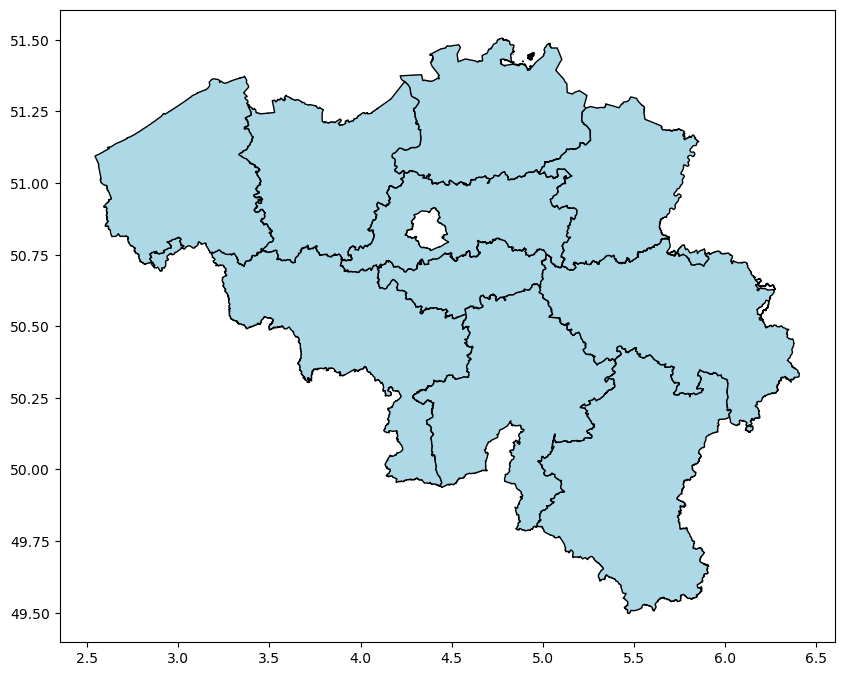

In [11]:
# Plot de kaart met provincies
fig, ax = plt.subplots(figsize=(10, 10))
provinces.plot(ax=ax, color='lightblue', edgecolor='black')
plt.show()

#### Omzetten van een adres naar een geocode
je kunt een adres omzetten naar geografische coördinaten (geocoderen) met behulp van verschillende online diensten zoals Geopy, Google Maps API, Nominatim (OpenStreetMap), en andere geocoding-tools. Hier is een voorbeeld met de Geopy-bibliotheek, die de Nominatim-service van OpenStreetMap gebruikt om een adres om te zetten naar coördinaten.

Bij het geocoderen met Geopy en de Nominatim-service (van OpenStreetMap), worden de coördinaten standaard geretourneerd in het EPSG:4326 coördinatenreferentiesysteem, ook bekend als WGS 84.

In [5]:
from geopy.geocoders import Nominatim

# Maak een geocoder object
geolocator = Nominatim(user_agent="mijn_code")

# Het adres dat je wilt geocoderen
address = "Spoorwegstraat 14, 8200 Brugge"

# Geocodeer het adres
location = geolocator.geocode(address)

# Print de coördinaten van het adres
if location:
    print(f"Geocodeerde coördinaten: Latitude: {location.latitude}, Longitude: {location.longitude}")
else:
    print("Adres niet gevonden")

def address_converter(address):
    # Geocodeer het adres
    return geolocator.geocode(address)

Geocodeerde coördinaten: Latitude: 51.1927178, Longitude: 3.218845351599427


#### Geef alles sites van Syntra weer als punten op de kaart.  Zorg dat de kaart overzichtelijk blijft.

In [22]:
# Oplossing

# We maken een punt per Syntra site.  Een punt heeft een latitude en een longitude.
dataset = {'adres':[],
          'latitude':[],
          'longitude':[]}

for adres in syntra_adressen:
    locatie = address_converter(adres)
    if locatie:
        dataset['adres'].append(adres)
        dataset['latitude'].append(locatie.latitude)
        dataset['longitude'].append(locatie.longitude)
    
# Maak een pandas dataframe
dataset_syntra = pd.DataFrame(dataset)
dataset_syntra.head()

,adres,latitude,longitude
0,"Wijngaardveld 9, 9300 Aalst",50.960325,4.046611
1,"Borsbeeksebrug 32, 2600 Berchem",51.199314,4.433979
2,"Geldenaaksebaan 327, 3001 Heverlee",50.863263,4.711786
3,"Oude Baan 2, 2800 Mechelen",51.051299,4.459526
4,"Z.5 Mollem 20, 1730 Asse",50.915344,4.215330


In [23]:
# Maken van punten van de latitude en longitude
from shapely.geometry import Point

geometry = [Point(xy) for xy in zip(dataset_syntra['longitude'], dataset_syntra['latitude'])]

In [24]:
belgium.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [25]:
# GeoDataFrame maken
gdf = gpd.GeoDataFrame(dataset_syntra, geometry=geometry)

# Coordinatenstelsel instellen
gdf.set_crs(epsg=4326, inplace=True)

gdf.head()

,adres,latitude,longitude,geometry
0,"Wijngaardveld 9, 9300 Aalst",50.960325,4.046611,POINT (4.04661 50.96032)
1,"Borsbeeksebrug 32, 2600 Berchem",51.199314,4.433979,POINT (4.43398 51.19931)
2,"Geldenaaksebaan 327, 3001 Heverlee",50.863263,4.711786,POINT (4.71179 50.86326)
3,"Oude Baan 2, 2800 Mechelen",51.051299,4.459526,POINT (4.45953 51.0513)
4,"Z.5 Mollem 20, 1730 Asse",50.915344,4.215330,POINT (4.21533 50.91534)


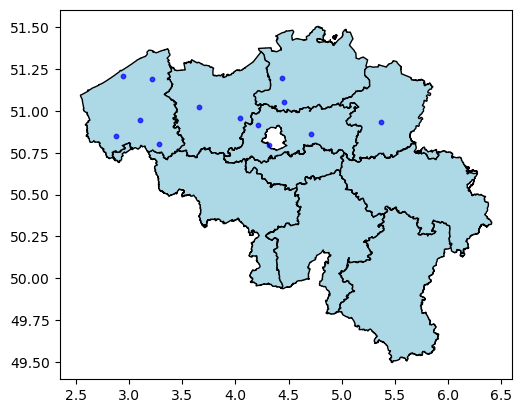

In [29]:
fig, ax = plt.subplots()
provinces.plot(ax=ax, color='lightblue', edgecolor='black')
ax.scatter(gdf['longitude'], gdf['latitude'], c='blue', s=10, alpha=0.7)

#### Oefening: maak een kaart van Vlaanderen met daarin alle gemeentes.  Visualiseer het inkomen per gemeente met een geschikte kleur.

In [59]:
# Oplossing
incomes = pd.read_csv('inkomen_per_gemeente.csv', sep=';')
# Vlaams Gewest als gemeente Eruit
incomes = incomes[incomes['Gemeente'] != 'Vlaams Gewest']

# Enkel meest recente jaar overhouden, zijnde 2021
incomes = incomes[incomes['Jaar'] == 2021]

incomes.head(2)

,Gemeente,NIS-code,Indicator,Jaar,Totaal netto belastbaar inkomen (in miljoen euro),Aantal inwoners,"Gemiddeld inkomen (in euro), per inwoner"
49,Aartselaar,11001,"Gemiddeld inkomen, per inwoner",2021,"371,377",14455,25692
74,Antwerpen,11002,"Gemiddeld inkomen, per inwoner",2021,"9506,27",529417,"17956,1"


In [62]:
# Mergen van de dataframes:
# Hierboven waren we tot de conclusie gekomen dat level 9 de gemeenten waren
gemeenten = belgium[belgium['admin_level'] == 9]

# Rename de kolom name naar Gemeente
gemeenten = gemeenten.rename(columns={'name':'Gemeente'})


gemeenten.head()

,admin_level,osm_admin_level,Gemeente,name_en,population,hasc,geometry
55,9,8,Tenneville,None,2861.0,None,"MULTIPOLYGON (((5.39024 50.07851, 5.39032 50.0..."
56,9,8,Rendeux,None,2596.0,None,"MULTIPOLYGON (((5.44198 50.22504, 5.44237 50.2..."
57,9,8,Boechout,None,12318.0,None,"MULTIPOLYGON (((4.47911 51.16276, 4.47986 51.1..."
58,9,8,Ville de Bruxelles - Stad Brussel,Brussels,220447.0,None,"MULTIPOLYGON (((4.314 50.8934, 4.318 50.89451,..."
59,9,8,Spiere-Helkijn,None,1939.0,None,"MULTIPOLYGON (((3.32376 50.72324, 3.32429 50.7..."


In [63]:
merged_dataset = pd.merge(gemeenten, incomes, on='Gemeente', how='left')
merged_dataset.head()

,admin_level,osm_admin_level,Gemeente,name_en,population,hasc,geometry,NIS-code,Indicator,Jaar,Totaal netto belastbaar inkomen (in miljoen euro),Aantal inwoners,"Gemiddeld inkomen (in euro), per inwoner"
0,9,8,Tenneville,None,2861.0,None,"MULTIPOLYGON (((5.39024 50.07851, 5.39032 50.0...",NaN,NaN,NaN,NaN,NaN,NaN
1,9,8,Rendeux,None,2596.0,None,"MULTIPOLYGON (((5.44198 50.22504, 5.44237 50.2...",NaN,NaN,NaN,NaN,NaN,NaN
2,9,8,Boechout,None,12318.0,None,"MULTIPOLYGON (((4.47911 51.16276, 4.47986 51.1...",11004.0,"Gemiddeld inkomen, per inwoner",2021.0,"343,389",13527.0,"25385,4"
3,9,8,Ville de Bruxelles - Stad Brussel,Brussels,220447.0,None,"MULTIPOLYGON (((4.314 50.8934, 4.318 50.89451,...",NaN,NaN,NaN,NaN,NaN,NaN
4,9,8,Spiere-Helkijn,None,1939.0,None,"MULTIPOLYGON (((3.32376 50.72324, 3.32429 50.7...",34043.0,"Gemiddeld inkomen, per inwoner",2021.0,"41,7491",2076.0,"20110,4"


<Axes: >

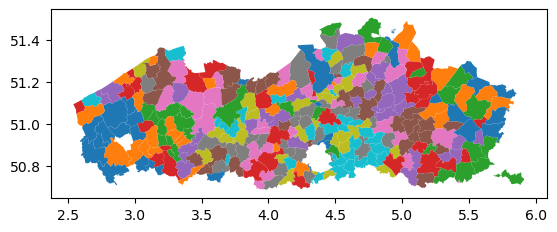

In [66]:
merged_dataset.plot(column='Gemiddeld inkomen (in euro), per inwoner')